In [1]:
import yfinance as yf
import datetime as dt
import pandas as pd
import numpy as np
from numpy import arange
import matplotlib.pyplot as plt
from sklearn import metrics, tree
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, export_graphviz
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RandomizedSearchCV

In [2]:
sp500data = yf.download("^GSPC", start="2017-01-01", end="2022-12-1")


/tmp/ipykernel_1850/1307718475.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  sp500data = yf.download("^GSPC", start="2017-01-01", end="2022-12-1")
[*********************100%***********************]  1 of 1 completed


In [3]:
sp500_df = pd.DataFrame(sp500data)
sp500_df.to_csv("sp500_data.csv")

In [4]:
sp500_df

Price,Close,High,Low,Open,Volume
Ticker,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC
Date,,,,,
2017-01-03,2257.830078,2263.879883,2245.129883,2251.570068,3773010000
2017-01-04,2270.750000,2272.820068,2261.600098,2261.600098,3768890000
2017-01-05,2269.000000,2271.500000,2260.449951,2268.179932,3785080000
2017-01-06,2276.979980,2282.100098,2264.060059,2271.139893,3342080000
2017-01-09,2268.899902,2275.489990,2268.899902,2273.590088,3219730000
...,...,...,...,...,...
2022-11-23,4027.260010,4033.780029,3998.659912,4000.300049,3279720000
2022-11-25,4026.120117,4034.020020,4020.760010,4023.340088,1706460000


In [5]:
sp500_df.dtypes

,,0
Price,Ticker,
Close,^GSPC,float64
High,^GSPC,float64
Low,^GSPC,float64
Open,^GSPC,float64
Volume,^GSPC,int64


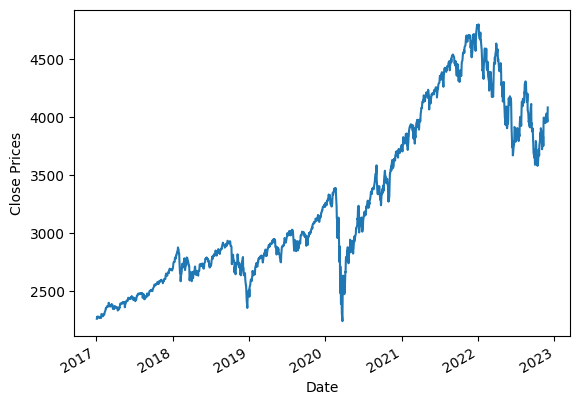

In [6]:
sp500_df.index.name = "Date"

# Plot the Close price of ^GSPC
sp500_df[('Close', '^GSPC')].plot()
plt.ylabel("Close Prices")
plt.show()

In [7]:
sp500_df.dropna(inplace=True)

In [8]:
df_lagged = sp500_df.copy()

In [9]:
df_lagged[('Open_Lag1', '^GSPC')] = df_lagged[('Open', '^GSPC')].shift(1)
df_lagged[('High_Lag1', '^GSPC')] = df_lagged[('High', '^GSPC')].shift(1)
df_lagged[('Low_Lag1', '^GSPC')] = df_lagged[('Low', '^GSPC')].shift(1)
df_lagged[('Close_Lag1', '^GSPC')] = df_lagged[('Close', '^GSPC')].shift(1)
df_lagged[('Volume_Lag1', '^GSPC')] = df_lagged[('Volume', '^GSPC')].shift(1)

In [10]:
df_lagged.dropna(inplace=True)

In [11]:
lag_features = [
    ('Open_Lag1', '^GSPC'),
    ('High_Lag1', '^GSPC'),
    ('Low_Lag1', '^GSPC'),
    ('Close_Lag1', '^GSPC'),
    ('Volume_Lag1', '^GSPC')
]

X_lag = df_lagged[lag_features].values
y_lag = df_lagged[('Close', '^GSPC')].values

In [12]:
X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(X_lag, y_lag, test_size=0.26, shuffle=False)

In [13]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_l)
X_test_scaled = scaler.transform(X_test_l)

In [14]:
model_lag = DecisionTreeRegressor(random_state=42, max_depth=8, min_samples_split=5)
model_lag.fit(X_train_scaled, y_train_l)
predict_lag = model_lag.predict(X_test_scaled)

In [15]:
print("Mean Absolute Error:", round(metrics.mean_absolute_error(y_test_l, predict_lag), 4))
print("Mean Squared Error:", round(metrics.mean_squared_error(y_test_l, predict_lag), 4))
print("Root Mean Squared Error:", round(np.sqrt(metrics.mean_squared_error(y_test_l, predict_lag)), 4))
print("R2 Score:", round(metrics.r2_score(y_test_l, predict_lag), 4))

Mean Absolute Error: 199.1091
Mean Squared Error: 67168.4792
Root Mean Squared Error: 259.1688
R2 Score: 0.2703


In [16]:
errors_l = abs(predict_lag - y_test_l)
mape_l = 100 * (errors_l / y_test_l)
print("Accuracy (MAPE-based):", round(100 - np.mean(mape_l), 2), "%")

Accuracy (MAPE-based): 95.53 %


In [17]:
predictions = pd.DataFrame({"Predictions": predict_lag}, index=pd.date_range(start=df_lagged.index[-1], periods=len(predict_lag), freq="B"))
predictions.to_csv("Predicted-price-data.csv")

predictions.iloc[:252].to_csv("one-year-predictions.csv")
predictions.iloc[:21].to_csv("one-month-predictions.csv")
predictions.iloc[:5].to_csv("five-days-predictions.csv")

Buy price and date:
            Predictions
2023-11-13  3974.540039

Sell price and date:
            Predictions
2022-12-02  4207.280111
2022-12-29  4207.280111
2023-08-29  4207.280111
2023-09-08  4207.280111
2023-09-14  4207.280111
2023-10-27  4207.280111
2023-10-31  4207.280111
2023-11-02  4207.280111
2023-11-03  4207.280111


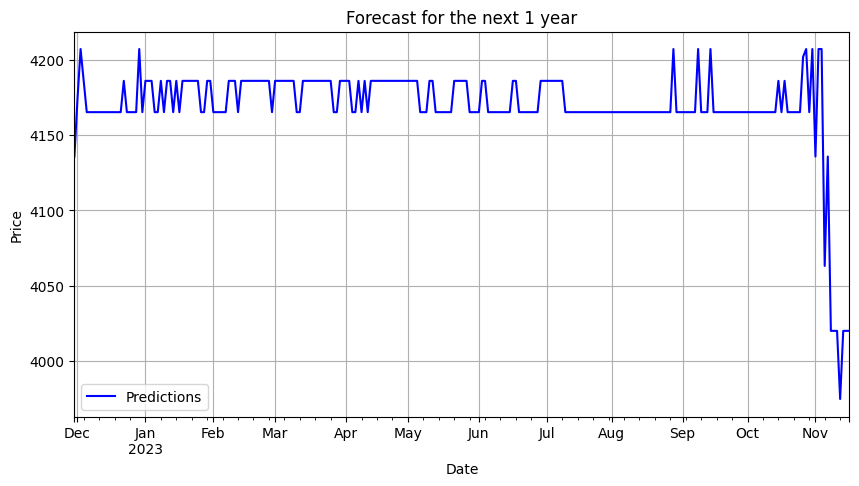

In [18]:
oneyear_df_pred = predictions.iloc[:252]

buy_price = oneyear_df_pred["Predictions"].min()
sell_price = oneyear_df_pred["Predictions"].max()

oneyear_buy = oneyear_df_pred[oneyear_df_pred["Predictions"] == buy_price]
oneyear_sell = oneyear_df_pred[oneyear_df_pred["Predictions"] == sell_price]

print("Buy price and date:")
print(oneyear_buy)
print("\nSell price and date:")
print(oneyear_sell)

oneyear_df_pred["Predictions"].plot(figsize=(10, 5), title="Forecast for the next 1 year", color="blue")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend(["Predictions"])
plt.grid(True)
plt.show()

In [19]:
onemonth_pred = predictions.iloc[:21]
buy_info = onemonth_pred[onemonth_pred["Predictions"] == onemonth_pred["Predictions"].min()]
sell_info = onemonth_pred[onemonth_pred["Predictions"] == onemonth_pred["Predictions"].max()]

Buy price and date:
            Predictions
2022-11-30  4135.785034

Sell price and date:

            Predictions
2022-12-02  4207.280111


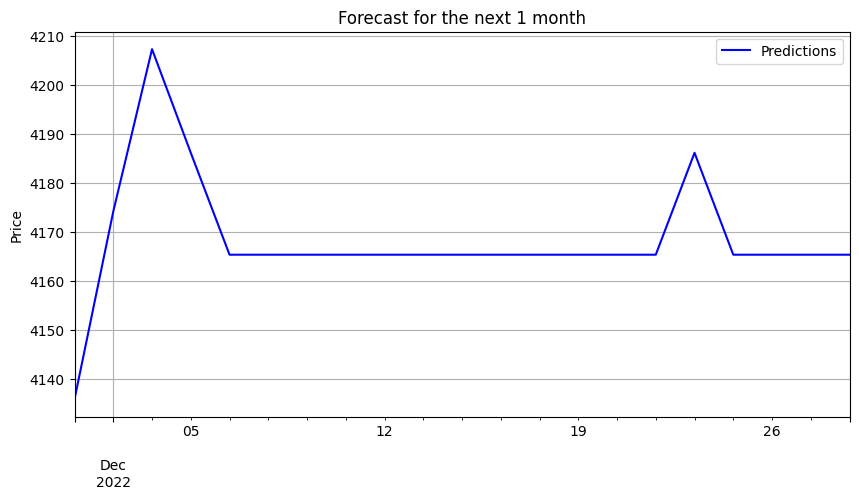

In [20]:
print("Buy price and date:")
print(buy_info)
print("\nSell price and date:\n")
print(sell_info)

onemonth_pred.plot(figsize=(10, 5), title="Forecast for the next 1 month", color="blue")
plt.ylabel("Price")
plt.grid(True)
plt.show()

Buy price and date (5 Days):
            Predictions
2022-11-30  4135.785034

Sell price and date (5 Days):
            Predictions
2022-12-02  4207.280111


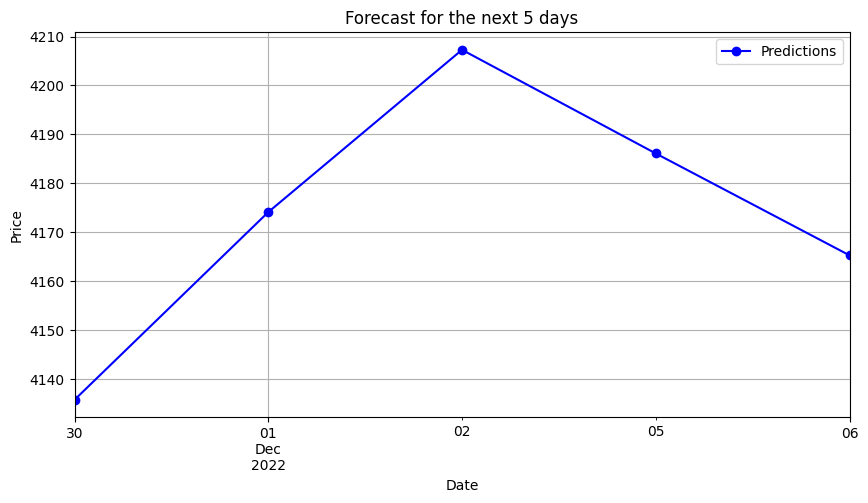

In [21]:
fivedays_df_pred = predictions.iloc[:5]

buy_price_5d = fivedays_df_pred["Predictions"].min()
sell_price_5d = fivedays_df_pred["Predictions"].max()

fivedays_buy = fivedays_df_pred[fivedays_df_pred["Predictions"] == buy_price_5d]
fivedays_sell = fivedays_df_pred[fivedays_df_pred["Predictions"] == sell_price_5d]

print("Buy price and date (5 Days):")
print(fivedays_buy)
print("\nSell price and date (5 Days):")
print(fivedays_sell)

fivedays_df_pred["Predictions"].plot(figsize=(10, 5), title="Forecast for the next 5 days", color="blue", marker="o")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend(["Predictions"])
plt.grid(True)
plt.show()

### Perbaikan Logika: Peramalan Rekursif Multi-Langkah (Recursive Multi-Step Forecasting)
Untuk meramal masa depan yang sebenarnya tanpa kebocoran data, kita akan mengambil baris data terakhir yang valid dari dataset kita, lalu secara iteratif memprediksi hari berikutnya dan memasukkan kembali hasil prediksi tersebut sebagai fitur lag untuk langkah prediksi selanjutnya.

In [22]:
# 1. Ambil data terakhir dari dataset asli untuk memulai peramalan
last_real_data = df_lagged.iloc[-1]

# Kita butuh scaler yang sudah dilatih sebelumnya (scaler)
# Fitur yang digunakan saat training: ['Open_Lag1', 'High_Lag1', 'Low_Lag1', 'Close_Lag1', 'Volume_Lag1']
# Kita inisialisasi input pertama dengan nilai riil terakhir
current_features = np.array([
    last_real_data[('Open', '^GSPC')],
    last_real_data[('High', '^GSPC')],
    last_real_data[('Low', '^GSPC')],
    last_real_data[('Close', '^GSPC')],
    last_real_data[('Volume', '^GSPC')]
]).reshape(1, -1)

forecasted_prices = []
steps = 30  # Kita ramal 30 hari bursa ke depan

for i in range(steps):
    # Standarisasi fitur menggunakan scaler yang sama
    current_features_scaled = scaler.transform(current_features)

    # Prediksi harga Close untuk langkah berikutnya
    next_close = model_lag.predict(current_features_scaled)[0]
    forecasted_prices.append(next_close)

    # Perbarui fitur untuk langkah berikutnya secara logis:
    # Karena Decision Tree membutuhkan Open, High, Low, Close, dan Volume,
    # kita asumsikan untuk proyeksi sederhana bahwa harga Open, High, Low berikutnya mendekati hasil prediksi Close
    # dan Volume tetap konstan menggunakan volume terakhir.
    current_features = np.array([
        next_close,             # Estimasi Open berikutnya
        next_close * 1.005,     # Estimasi High berikutnya
        next_close * 0.995,     # Estimasi Low berikutnya
        next_close,             # Close hasil prediksi
        current_features[0, 4]  # Volume konstan
    ]).reshape(1, -1)

# Buat index tanggal masa depan (hari kerja)
start_date = df_lagged.index[-1] + pd.Timedelta(days=1)
forecast_dates = pd.date_range(start=start_date, periods=steps, freq='B')

# Simpan ke DataFrame baru
recursive_forecast_df = pd.DataFrame({"Forecast_Close": forecasted_prices}, index=forecast_dates)
display(recursive_forecast_df.head(10))


,Forecast_Close
2022-12-01,4019.870117
2022-12-02,4019.870117
2022-12-05,4019.870117
2022-12-06,4019.870117
2022-12-07,4019.870117
2022-12-08,4019.870117
2022-12-09,4019.870117
2022-12-12,4019.870117
2022-12-13,4019.870117
2022-12-14,4019.870117


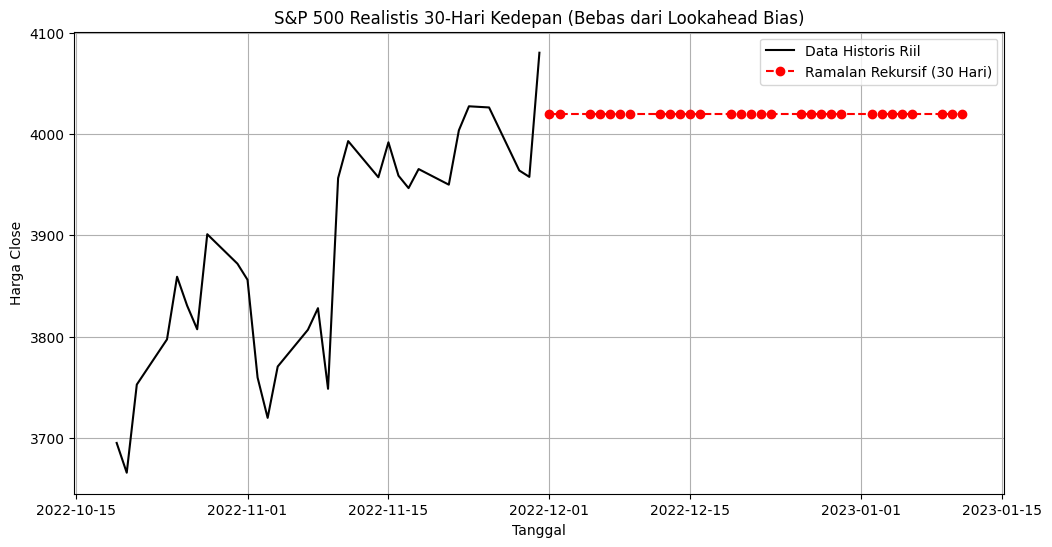

In [23]:
# 2. Visualisasikan hasil peramalan rekursif yang benar secara logika
plt.figure(figsize=(12, 6))
# Plot data historis 30 hari terakhir
plt.plot(df_lagged.index[-30:], df_lagged[('Close', '^GSPC')].iloc[-30:], label="Data Historis Riil", color="black")
# Plot hasil ramalan 30 hari ke depan
plt.plot(recursive_forecast_df.index, recursive_forecast_df["Forecast_Close"], label="Ramalan Rekursif (30 Hari)", color="red", linestyle="--", marker="o")

plt.title("S&P 500 Realistis 30-Hari Kedepan (Bebas dari Lookahead Bias)")
plt.xlabel("Tanggal")
plt.ylabel("Harga Close")
plt.legend()
plt.grid(True)
plt.show()


In [24]:
text_representation = tree.export_text(model_lag)
print(text_representation)

|--- feature_3 <= 0.58
|   |--- feature_2 <= -0.58
|   |   |--- feature_0 <= -0.95
|   |   |   |--- feature_3 <= -1.14
|   |   |   |   |--- feature_3 <= -1.34
|   |   |   |   |   |--- feature_2 <= -1.54
|   |   |   |   |   |   |--- value: [2447.33]
|   |   |   |   |   |--- feature_2 >  -1.54
|   |   |   |   |   |   |--- feature_2 <= -1.37
|   |   |   |   |   |   |   |--- feature_4 <= 2.39
|   |   |   |   |   |   |   |   |--- value: [2280.40]
|   |   |   |   |   |   |   |--- feature_4 >  2.39
|   |   |   |   |   |   |   |   |--- value: [2237.40]
|   |   |   |   |   |   |--- feature_2 >  -1.37
|   |   |   |   |   |   |   |--- value: [2322.18]
|   |   |   |   |--- feature_3 >  -1.34
|   |   |   |   |   |--- feature_1 <= -1.22
|   |   |   |   |   |   |--- feature_2 <= -1.24
|   |   |   |   |   |   |   |--- feature_2 <= -1.26
|   |   |   |   |   |   |   |   |--- value: [2347.67]
|   |   |   |   |   |   |   |--- feature_2 >  -1.26
|   |   |   |   |   |   |   |   |--- value: [2358.75]
|   |  